## MTL Trajet: 23 Intermediate Stop Daily Chain Patterns (Flag 23)

### Dataset Overview

Complete connected daily chains with intermediate-stop area, activity, duration, subsequent purpose and distance, transport mode, and timestamped trajectory points.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze mobility patterns around intermediate stops in daily trip chains.

Role: Urban mobility-pattern analyst


Category: Complete connected daily chains with intermediate-stop area, activity, duration, subsequent purpose and distance, transport mode, and timestamped trajectory points.

Distances and directness are calculated from delivered GPS polylines; point speeds, trip durations, chain timing, and paired-leg timing are synchronized with the supplied point table. Route directness ratio is route distance divided by straight-line distance, so it is at least 1 and lower values indicate more direct routes.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which area types host the widest range of intermediate-stop activities, and how do those stops connect to following trips including return home?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

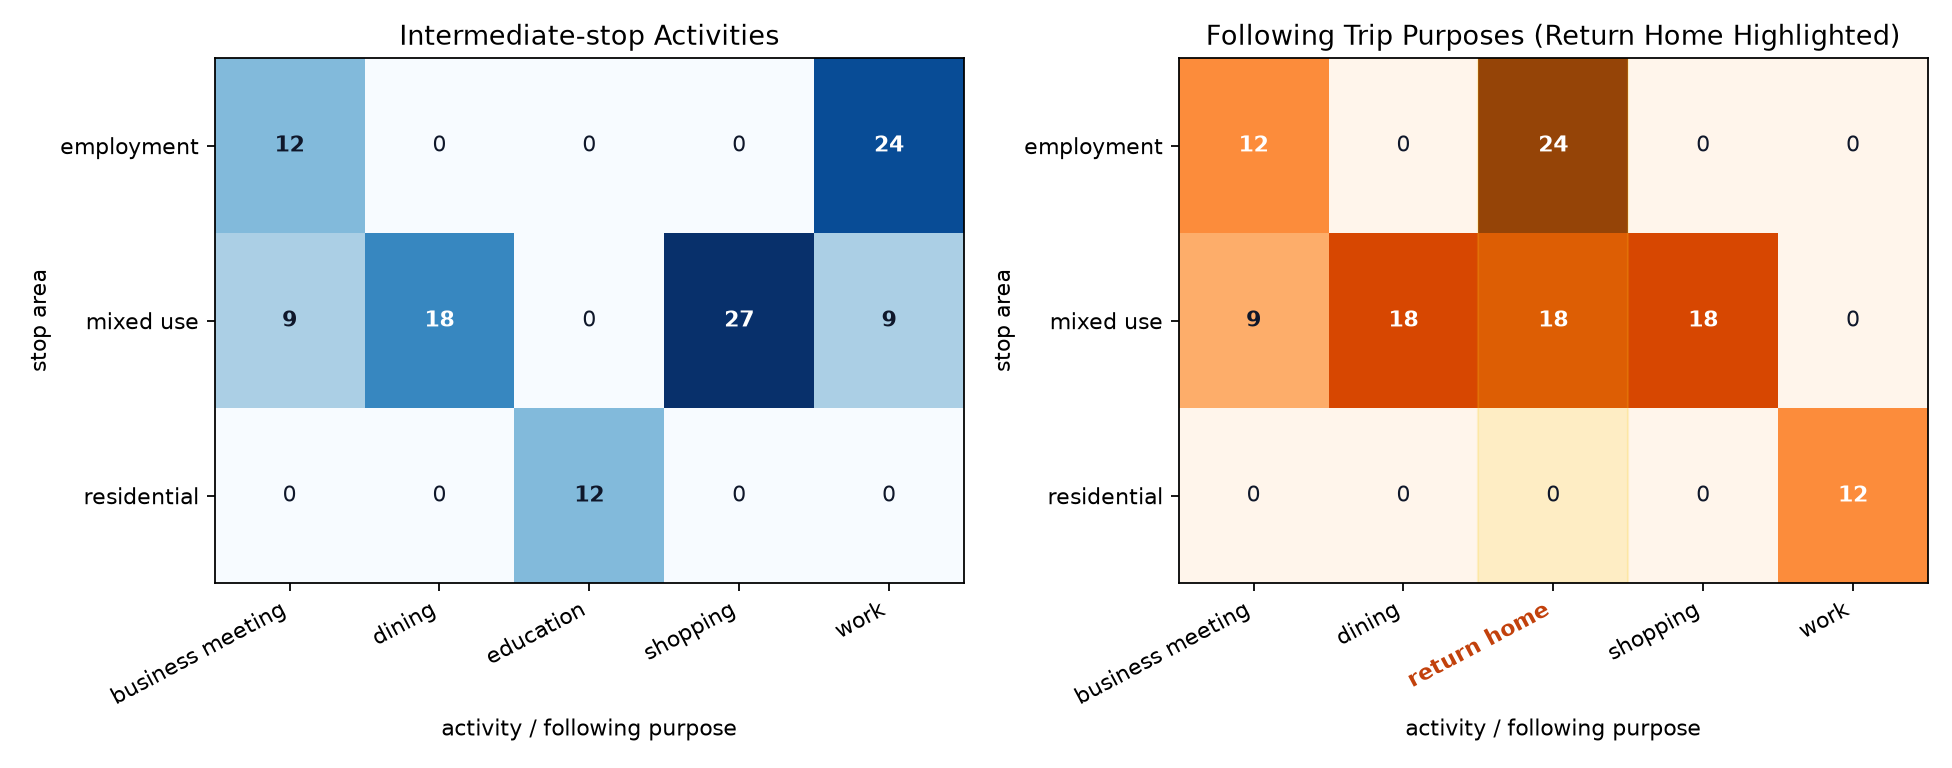

In [ ]:
stops = df[df.is_intermediate_stop]
activity_counts = pd.crosstab(stops.stop_area_type, stops.stop_activity)
following_counts = pd.crosstab(stops.stop_area_type, stops.next_trip_purpose)
display(activity_counts, following_counts)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/stop_area_activity_variety.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "intermediate_stop_variety",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Intermediate-stop Variety by Area",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/stop_area_activity_variety.png"
  },
  "question": "Which area types host the widest range of intermediate-stop activities, and how do those stops connect to following trips including return home?",
  "code": "stops=df[df.is_intermediate_stop]; activity_counts=pd.crosstab(stops.stop_area_type,stops.stop_activity); following_counts=pd.crosstab(stops.stop_area_type,stops.next_trip_purpose); display(activity_counts,following_counts)",
  "insight": "Mixed-use areas host the widest variety of intermediate stops, connecting work, shopping, dining, and return-home trips within the same daily chains.",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "trip_purpose",
    "gps_position"
  ]
}

### **Question 2**: What commonly follows short midday stops, and which activities account for longer stops across the daytime?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

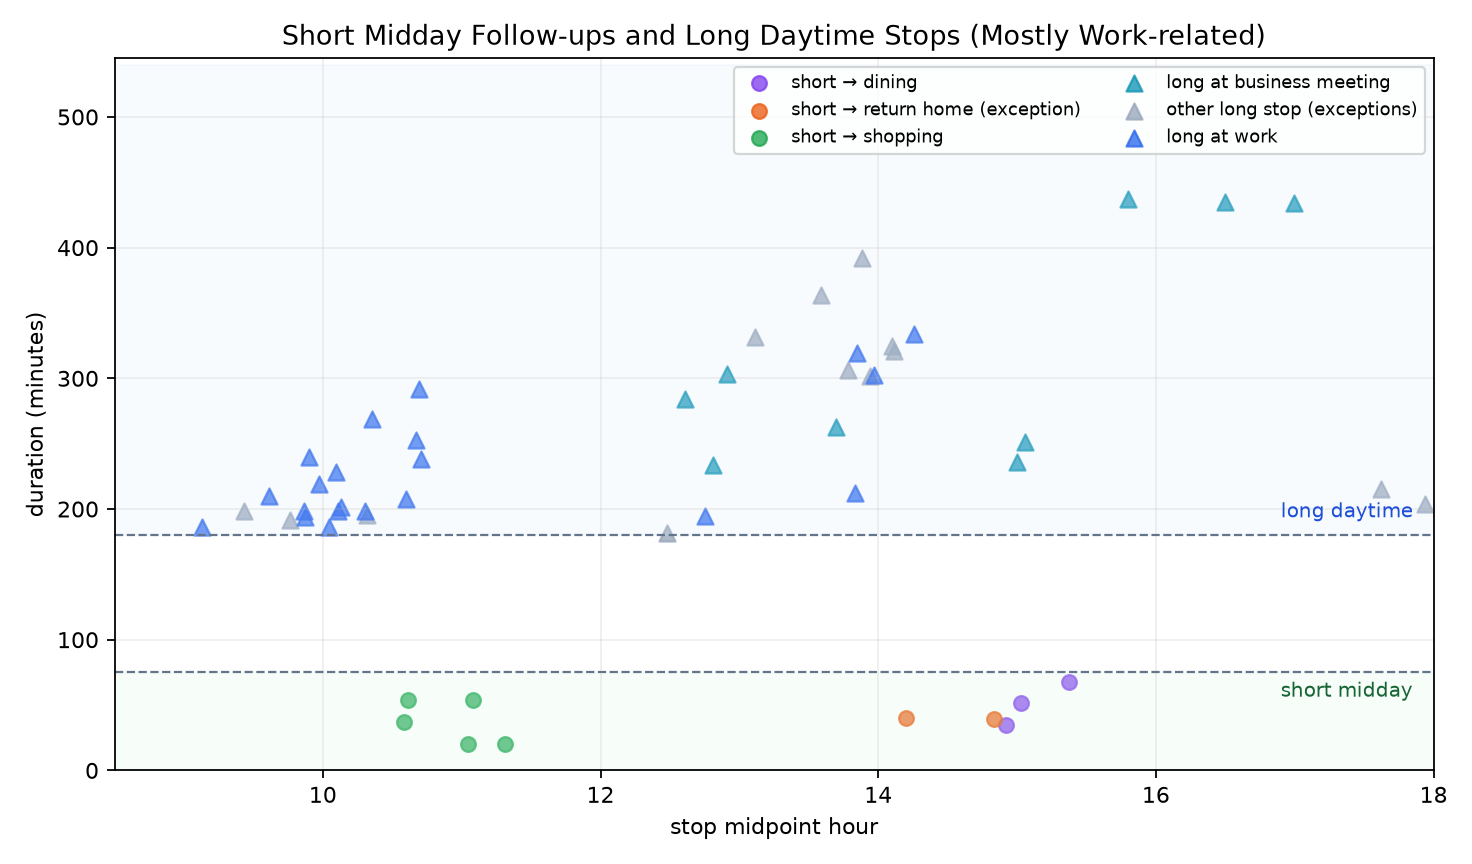

In [ ]:
stops = df[df.is_intermediate_stop]
short_midday = stops[
    (stops.stop_duration_minutes < 75) & stops.stop_midpoint_hour.between(10.5, 15.8)
]
long_daytime = stops[
    (stops.stop_duration_minutes >= 180) & stops.stop_midpoint_hour.between(8.5, 18)
]
display(
    short_midday.groupby("next_trip_purpose").size(),
    long_daytime.groupby("stop_activity").size(),
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/stop_duration_next_purpose.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "stop_duration_timing_followup",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Stop Timing, Duration, and Follow-up",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/stop_duration_next_purpose.png"
  },
  "question": "What commonly follows short midday stops, and which activities account for longer stops across the daytime?",
  "code": "stops=df[df.is_intermediate_stop]; short_midday=stops[(stops.stop_duration_minutes<75)&stops.stop_midpoint_hour.between(10.5,15.8)]; long_daytime=stops[(stops.stop_duration_minutes>=180)&stops.stop_midpoint_hour.between(8.5,18)]; display(short_midday.groupby('next_trip_purpose').size(),long_daytime.groupby('stop_activity').size())",
  "insight": "Short midday stops are commonly followed by shopping or dining trips, while longer daytime stops more often separate work-related movements.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id",
    "user_id"
  ]
}

### **Question 3**: How does stop duration relate to changes in next-trip distance, purpose, and mode?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

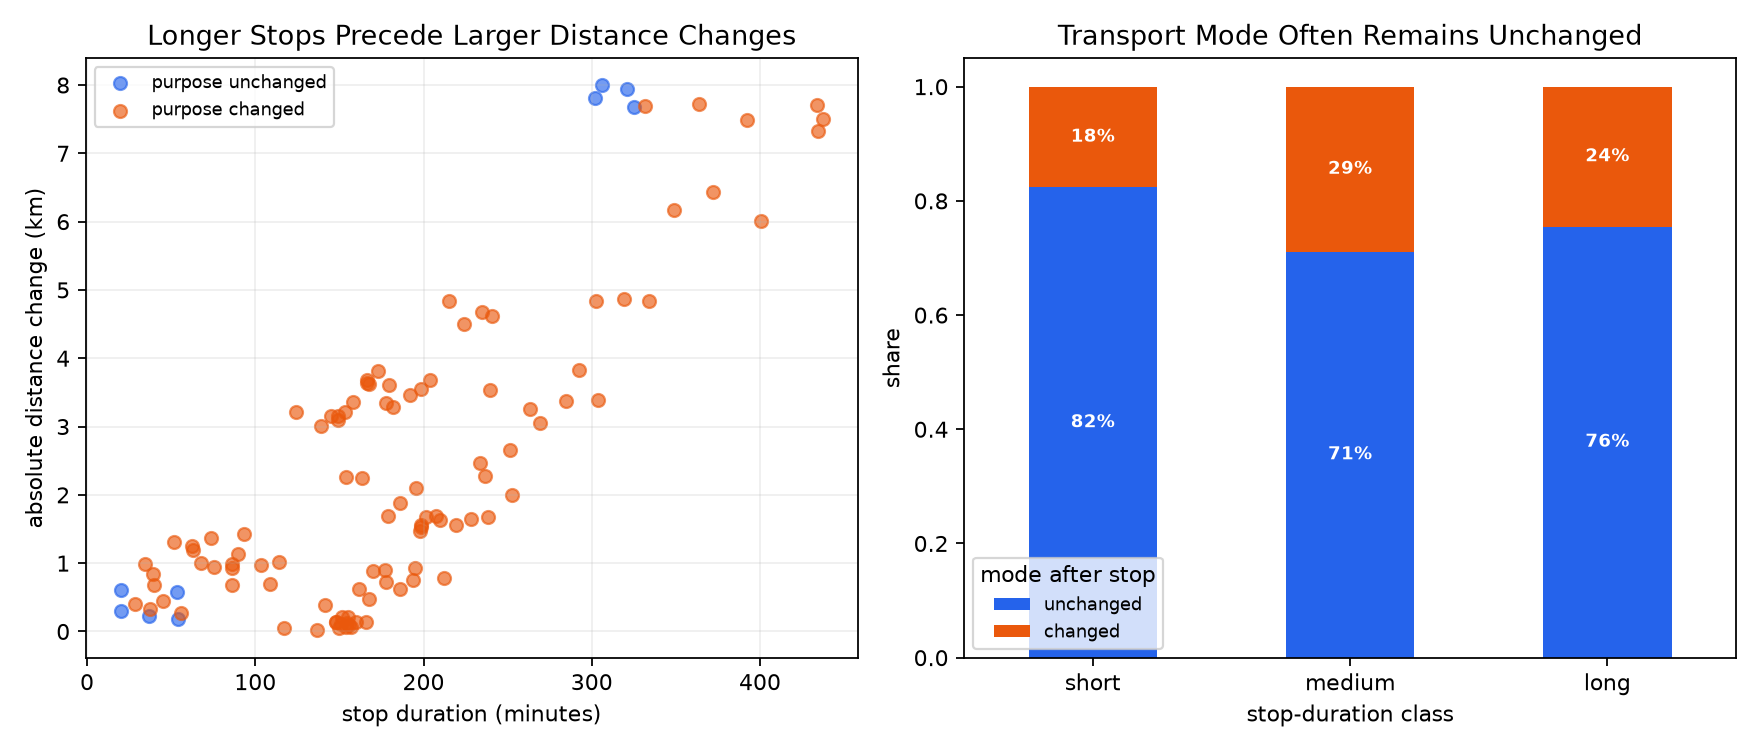

In [ ]:
stops = df[df.is_intermediate_stop]
stops.groupby(pd.cut(stops.stop_duration_minutes, [0, 75, 180, 600]), observed=False)[
    ["distance_change_km", "purpose_changed", "mode_changed"]
].mean()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/stop_duration_distance_purpose_mode.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "stop_duration_change_relationship",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Stop Duration and Subsequent Change",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/stop_duration_distance_purpose_mode.png"
  },
  "question": "How does stop duration relate to changes in next-trip distance, purpose, and mode?",
  "code": "stops=df[df.is_intermediate_stop]; stops.groupby(pd.cut(stops.stop_duration_minutes,[0,75,180,600]),observed=False)[['distance_change_km','purpose_changed','mode_changed']].mean()",
  "insight": "Longer stop durations are associated with larger changes in subsequent trip distance and purpose, while transport mode often remains unchanged.",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "transport_mode",
    "gps_position"
  ]
}

### Summary of Findings (Flag 23)

Mixed-use areas host the broadest intermediate-stop activity mix. Short midday stops commonly lead to shopping or dining, whereas longer daytime stops separate work-related movements and precede larger changes in distance and purpose; modes usually persist.